*Name: Shayan Salehi*
*Student ID: 404203509*

Here we compute and display the magnitude and phase of the Fourier transform for each image.

First we read image, convert to grayscale, compute FFT2, center with fftshift, then display log(1+|F|) and phase.

In [ ]:
!pip install opencv-python

In [6]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [7]:
img_dir = Path("Figures")
exts = ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff")
paths = []
for e in exts:
    paths.extend(img_dir.glob(e))
paths = sorted(paths)
if not paths:
    raise FileNotFoundError("No images found in figure4")

In [8]:
def fft_parts(gray):
    F = np.fft.fft2(gray)
    Fshift = np.fft.fftshift(F)
    mag = np.log1p(np.abs(Fshift))
    phase = np.angle(Fshift)
    return mag, phase

In [9]:
def show_triplet(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        return
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    mag, phase = fft_parts(gray)
    mag = mag / (mag.max() + 1e-8)
    phase = (phase + np.pi) / (2 * np.pi)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(rgb)
    ax[0].set_title("Image")
    ax[0].axis("off")

    ax[1].imshow(mag, cmap="gray")
    ax[1].set_title("Magnitude (log)")
    ax[1].axis("off")

    ax[2].imshow(phase, cmap="gray")
    ax[2].set_title("Phase")
    ax[2].axis("off")

    fig.suptitle(path.name)
    plt.show()

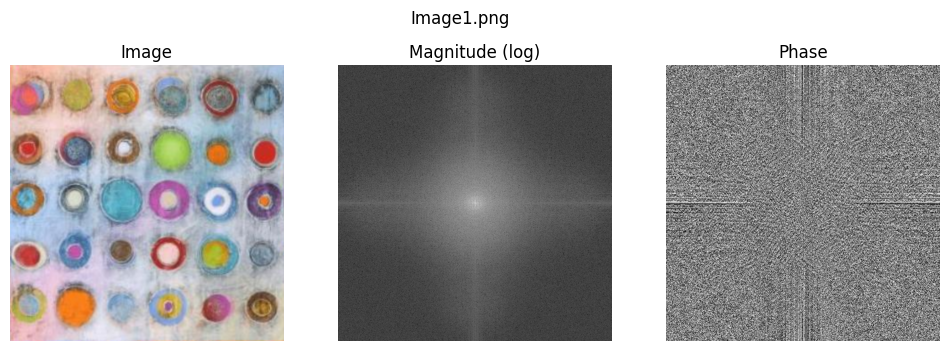

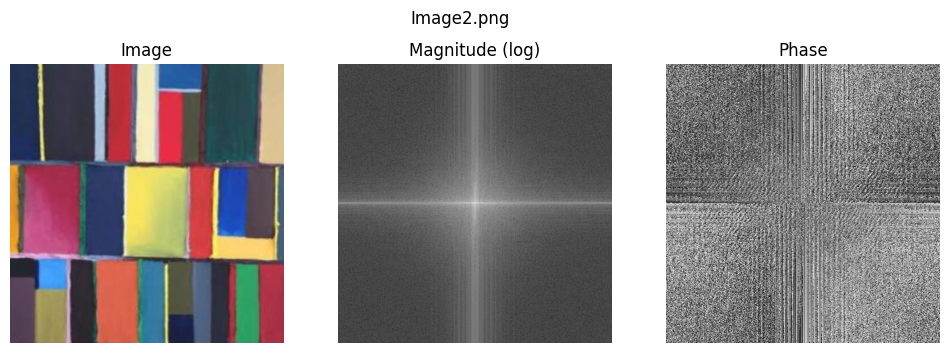

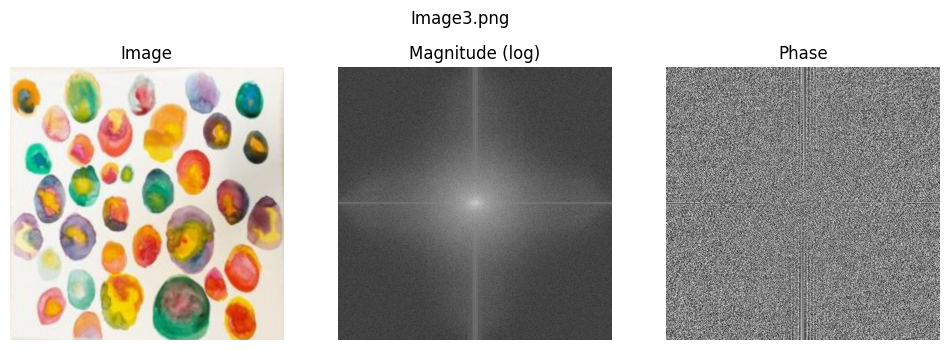

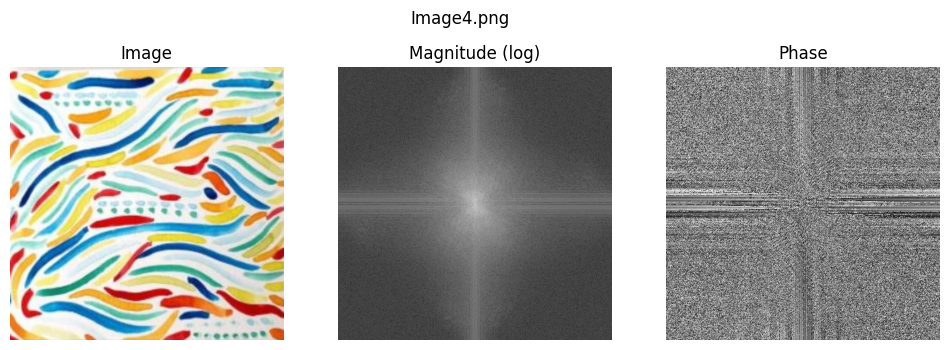

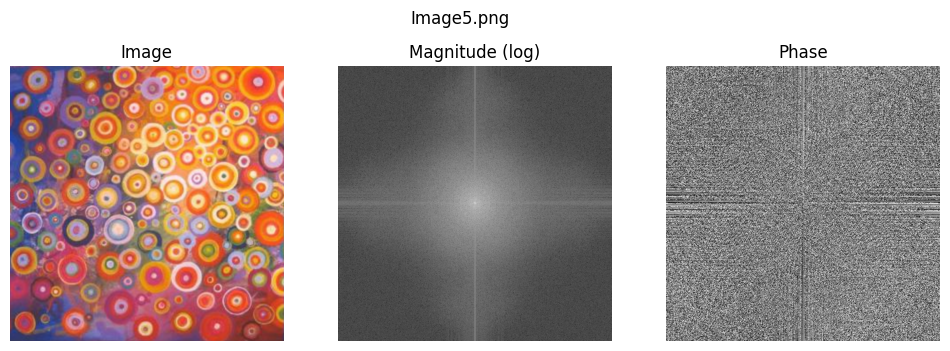

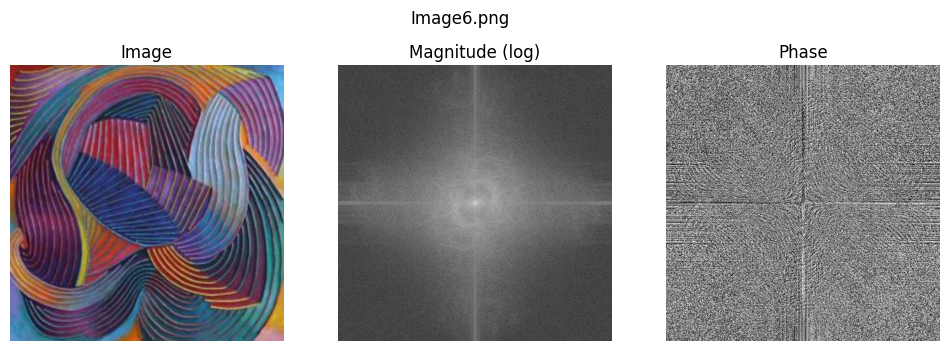

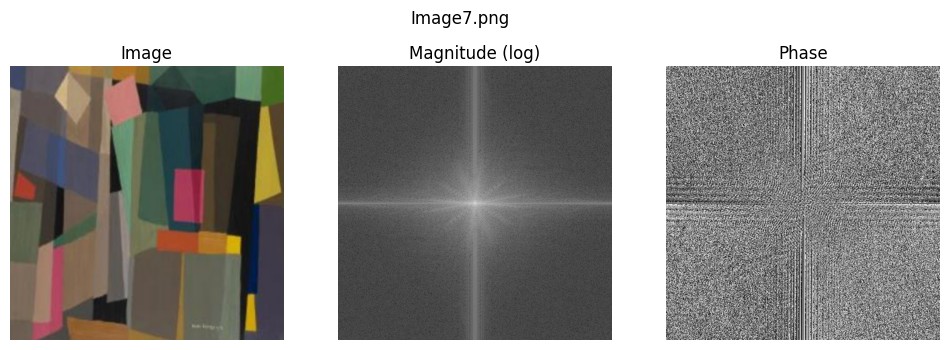

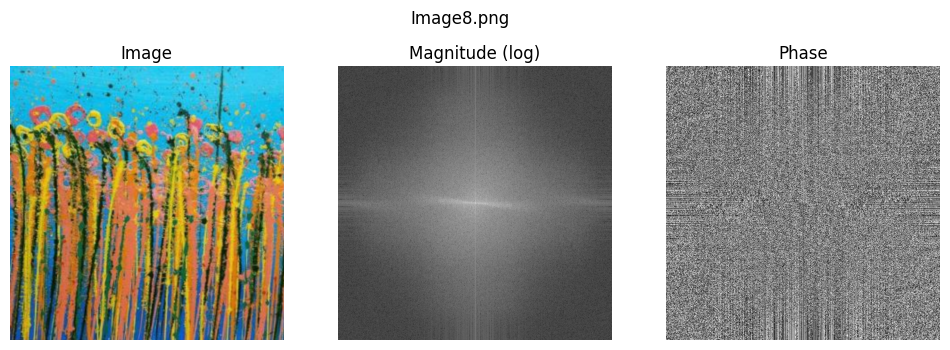

In [10]:
for p in paths:
    show_triplet(p)

The results will show different patterns in the magnitude and phase spectra for various image types:

Repetitive patterns: sharp peaks in the spectrum.

Directional edges: energy concentrated on the line perpendicular to the edge direction.

Smooth regions: energy concentrated in low frequencies near the center.

Irregular textures: a spread, broad spectrum.

Circular structures: circular symmetry in the spectrum.